# Load datasets

In [1]:
import pandas as pd
df_population = pd.read_parquet("assets/population.parquet")
df_test = pd.read_parquet("assets/test.parquet")
df_training = pd.read_parquet("assets/training.parquet")
df_anchors = pd.read_parquet("assets/anchors.parquet")

In [7]:
df_population.columns

Index(['investee_name', 'investee_nation', 'investee_trbc_economic_sector',
       'investment_date', 'round_number', 'investment_stage', 'firm_name',
       'fund_name', 'investor_equity_total',
       'fund_disclosed_equity_contribution', 'round_equity_total',
       'disclosed_debt_contribution', 'deal_value', 'deal_rank_value',
       'investee_all_firms', 'investee_all_funds', 'investee_ipo_date',
       'investee_is_sustainable', 'investee_technology_application',
       'investee_total_funding_received_to_date', 'investee_trbc_activity',
       'investee_trbc_business_sector', 'investee_trbc_industry',
       'investee_trbc_industry_group', 'investee_website', 'firm_aum',
       'firm_founded_date', 'firm_industry_focus', 'firm_investment_type',
       'firm_type', 'firm_number_funds', 'fund_founded_date',
       'fund_investor_type', 'fund_nation', 'fund_size', 'fund_stage',
       'fund_type', 'fund_number_investees', 'number_funds', 'firm_nation',
       'firm_website', 'inve

In [3]:
df_anchors

,name,label,constant_name,text,embedding
0,afolu,is_afolu,AFOLU,"Agriculture, forestry and other land uses miti...","[-0.041103527, -0.01283767, -0.0043540075, -0...."
1,buildings,is_buildings,BUILDINGS,Buildings mitigation options include improving...,"[-0.01900522, 0.00072043133, 0.00042394432, 0...."
2,cross_sectoral,is_cross_sectoral,CROSS_SECTORAL,Cross-sectoral mitigation options include (i) ...,"[-0.04816021, -0.030773552, -0.04342598, -0.01..."
3,cski,is_cski,CSKI,"Cities, settlements and key infrastructure ada...","[-0.021697467, 0.05040428, -0.024989644, 0.006..."
4,energy,is_energy,ENERGY,Energy system mitigation options include energ...,"[-0.024089998, 0.016496567, -0.026759364, -0.0..."
5,ffoep,is_ffoep,FFOEP,"Food, fibre and other ecosystem products adapt...","[-0.0065682344, 0.0021598642, -0.03205524, 0.0..."
6,health,is_health,HEALTH,"Health, wellbeing and the changing structure o...","[-0.0046466957, 0.02234277, -0.039635256, 0.02..."
7,industry,is_industry,INDUSTRY,Industry mitigation options include (i) decoup...,"[-0.05483165, 0.010528556, -0.018053336, 0.015..."
8,oce,is_oce,OCE,Oceans and coastal ecosystems adaptation optio...,"[0.0017009055, 0.010953454, -0.03471558, -0.00..."
9,tfe,is_tfe,TFE,Terrestrial and freshwater ecosystems adaptati...,"[-0.019001765, 0.0054529407, -0.057563532, 0.0..."


# Binary Logit

In [49]:
# Hyperparameter tuning
import importlib
import functions.binary_logit
importlib.reload(functions.binary_logit)
from functions.binary_logit import evaluate_binary_logit_grid

categories = df_anchors['label'].to_list()

# df_training['is_climate'] = True if any of the columns in categories are True, else False
df = df_training.copy()
df['is_climate'] = df[categories].any(axis=1)

df_results = evaluate_binary_logit_grid(
    df=df,
    y_label='is_climate',
    x_label='snapshot_emb',
    c_min=0.1,
    c_max=10,
    c_increment=0.1,
    tau_min=0.05,
    tau_max=0.95,
    tau_increment=0.05,
    split=0.2,
    n_rep=10,
    class_weight=None,
    random_state= 42,
)

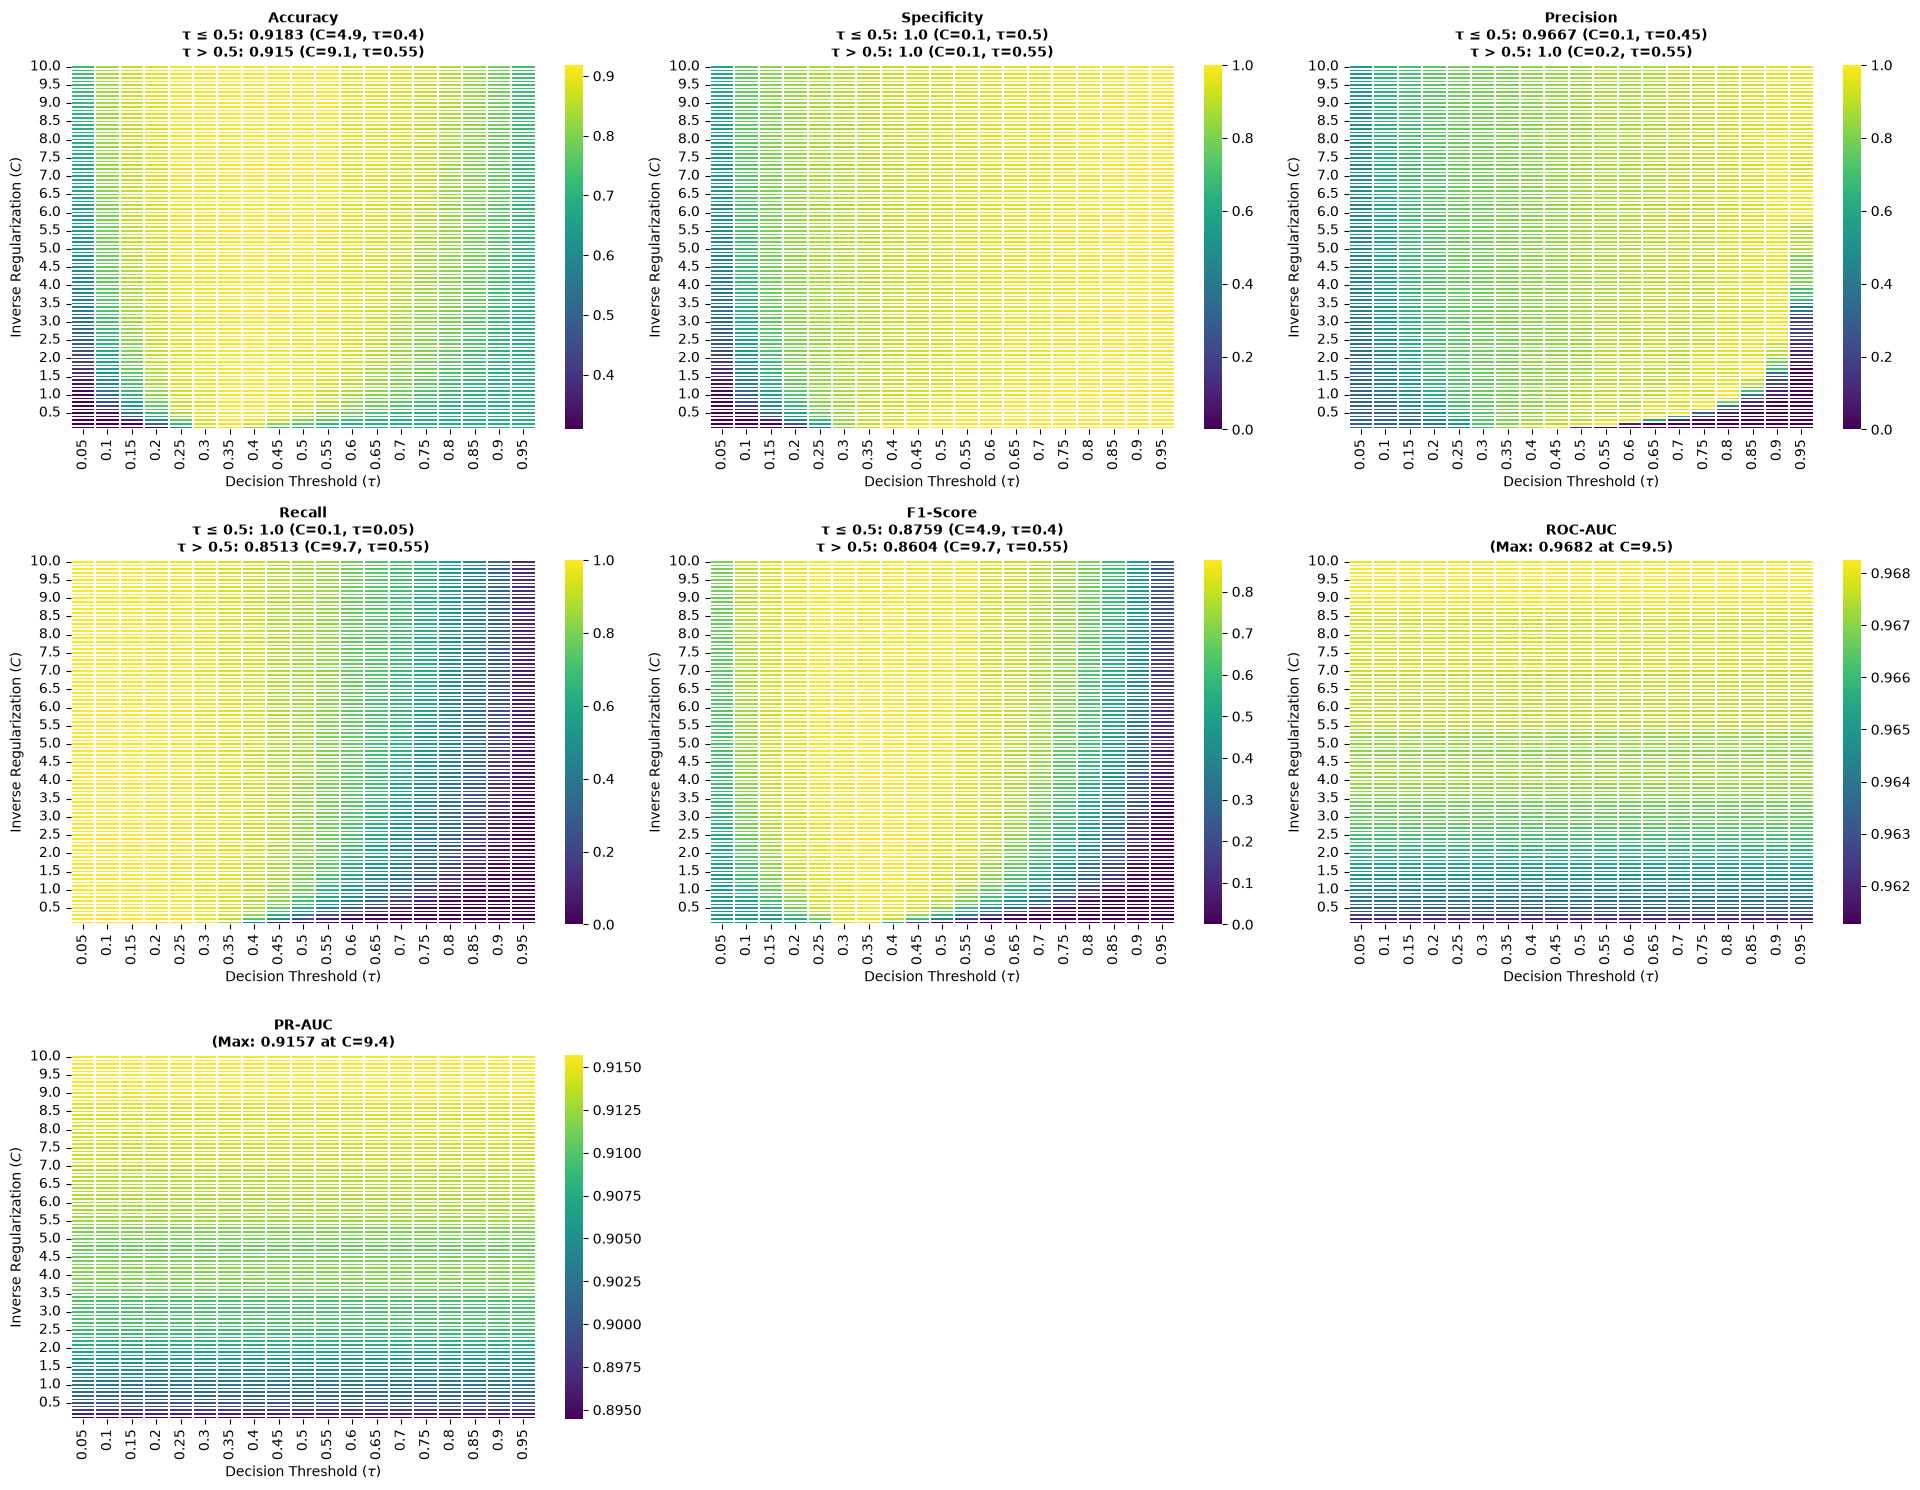


OPTIMAL HYPERPARAMETERS: LOW REGIME (τ ≤ 0.5) vs HIGH REGIME (τ > 0.5)
     Metric  C (τ ≤ 0.5) tau (τ ≤ 0.5)  Max Score (τ ≤ 0.5)  C (τ > 0.5) tau (τ > 0.5)  Max Score (τ > 0.5)
   Accuracy          4.9           0.4               0.9183          9.1          0.55               0.9150
Specificity          0.1           0.5               1.0000          0.1          0.55               1.0000
  Precision          0.1          0.45               0.9667          0.2          0.55               1.0000
     Recall          0.1          0.05               1.0000          9.7          0.55               0.8513
   F1-Score          4.9           0.4               0.8759          9.7          0.55               0.8604
    ROC-AUC          9.5   N/A (all τ)               0.9682          9.5   N/A (all τ)               0.9682
     PR-AUC          9.4   N/A (all τ)               0.9157          9.4   N/A (all τ)               0.9157


In [50]:
# Display results
import functions.display_hyperparameters
importlib.reload(functions.display_hyperparameters)
from functions.display_hyperparameters import display_hyperparameters

# Pass df_results directly
best_points_df = display_hyperparameters(df_results)

In [51]:
# Build the model with the best hyperparameters
import functions.binary_logit
importlib.reload(functions.binary_logit)
from functions.binary_logit import get_binary_logit_weights

df = df_training.copy()
df['is_climate'] = df[categories].any(axis=1)

# Train final model with the chosen C and tau
model_artifacts = get_binary_logit_weights(
    df=df,
    y_label="is_climate",
    x_label="snapshot_emb",
    c=9.7,  # Your chosen C
    tau=0.55,  # Your chosen tau
    class_weight=None,
)

# Extract raw weights vector (shape: 1024,)
w_vector = model_artifacts["weights"]
intercept = model_artifacts["intercept"]

print(f"Weight vector shape: {w_vector.shape}")
print(f"Intercept: {intercept:.4f}")
print(f"Decision threshold (tau): {model_artifacts['tau']}")

Weight vector shape: (1024,)
Intercept: -2.7414
Decision threshold (tau): 0.55


In [52]:
# Evaluate 
import functions.binary_logit
importlib.reload(functions.binary_logit)
from functions.binary_logit import (
    evaluate_model_artifacts,
    get_binary_logit_weights,
)

df = df_test.copy()
df['is_climate'] = df[categories].any(axis=1)

metrics_summary = evaluate_model_artifacts(
    df=df,
    y_label="is_climate",
    x_label="snapshot_emb",
    model_artifacts=model_artifacts,
)

print(metrics_summary.to_string(index=False))

  C  tau  Accuracy  Specificity  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
9.7 0.55    0.9783       0.9844     0.6897  0.8333    0.7547   0.9881  0.8339
